# BSDE-32 Deep BSDE Workspace

Implementation scaffold for the 5-5-1 Lucas Orchard described in `Tex/BSDE_32.tex`. The notebook mirrors the document's structure while wiring the JAX ecosystem (JAX, Equinox, Optax, Optimistix, JAXopt) required for high-dimensional Deep BSDE experiments.

## Notebook Roadmap
- Encode primitives and transformations from the 5-tree CRRA Lucas economy.
- Provide reusable JAX utilities for $(C,\mathbf{s})$ and log-ratio dynamics.
- Define Barrier-Ansatz neural networks with Equinox.
- Assemble Deep BSDE residuals, Malliavin penalties, and dual-measure checks.
- Sketch a training routine using Optax optimizers and RQMC-ready sampling.
- Include calibration helpers built with Optimistix and JAXopt.

In [ ]:
from __future__ import annotations
from typing import Any, Callable, Dict, Mapping, Tuple
from functools import partial

import jax
import jax.numpy as jnp
import equinox as eqx
import optax
import numpy as np
from cycler import cycler
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from jax import random

import optimistix as optx
from jaxopt import BFGS, ScipyMinimize

Array = jnp.ndarray




In [ ]:
mpl.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.titlesize': 18,
    'axes.titleweight': 'semibold',
    'axes.labelsize': 14,
    'axes.facecolor': '#f4f6fb',
    'figure.facecolor': 'white',
    'axes.edgecolor': '#1f2933',
    'axes.linewidth': 1.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#c7d0dd',
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
    'axes.prop_cycle': cycler(color=['#1d3557', '#e76f51', '#2a9d8f', '#457b9d', '#f4a261', '#606c38']),
    'legend.frameon': False,
    'legend.fontsize': 11,
    'figure.dpi': 120,
    'savefig.dpi': 220,
    'xtick.direction': 'inout',
    'ytick.direction': 'inout',
})
plt.rcParams['figure.figsize'] = (11.5, 6.5)
plt.rcParams['axes.formatter.useoffset'] = False


In [ ]:
# !pip install --upgrade jaxopt
# uv add optax equinox

In [ ]:
class LucasOrchardConfig(eqx.Module):
    """Structural parameters of the 5-5-1 Lucas orchard."""

    mu: Array  # shape (5,)
    sigma: Array  # shape (5, 5)
    rho: float
    gamma: float
    seed: int = 0

    @property
    def n_trees(self) -> int:
        return int(self.mu.shape[0])

    @property
    def dim_w(self) -> int:
        return int(self.sigma.shape[1])

    def split_key(self, key: random.PRNGKey) -> Tuple[random.PRNGKey, random.PRNGKey]:
        return random.split(key)


def default_config() -> LucasOrchardConfig:
    mu = jnp.array([0.025, 0.03, 0.028, 0.027, 0.026])
    sigma = jnp.array(
        [
            [0.18, 0.02, 0.01, 0.00, 0.00],
            [0.05, 0.16, 0.04, 0.01, 0.00],
            [0.03, 0.02, 0.17, 0.02, 0.01],
            [0.02, 0.03, 0.04, 0.15, 0.03],
            [0.01, 0.01, 0.02, 0.03, 0.16],
        ]
    )
    return LucasOrchardConfig(mu=mu, sigma=sigma, rho=0.04, gamma=6.0)


In [ ]:
def aggregate_drifts(config: LucasOrchardConfig, s: Array) -> Tuple[Array, Array]:
    mu_c = jnp.einsum("...i,i->...", s, config.mu)
    sigma_c = jnp.einsum("...i,ij->...j", s, config.sigma)
    return mu_c, sigma_c

In [ ]:
def kappa_gamma(config: LucasOrchardConfig, shares: Array) -> Array:
    """Effective discount rate kappa_gamma(s) from the PDE."""
    mu_c, sigma_c = aggregate_drifts(config, shares)
    sigma_norm_sq = jnp.sum(jnp.square(sigma_c), axis=-1)
    return config.rho + (config.gamma - 1.0) * mu_c + 0.5 * config.gamma * (1.0 - config.gamma) * sigma_norm_sq


In [ ]:
def share_drift(config: LucasOrchardConfig, shares: Array) -> Array:
    """Physical share drift mu_s from Lemma 4.1."""
    shares = jnp.asarray(shares)
    mu_i = jnp.asarray(config.mu)
    mu_c, sigma_c = aggregate_drifts(config, shares)
    sigma_norm_sq = jnp.sum(jnp.square(sigma_c), axis=-1, keepdims=True)
    sigma_dot = jnp.einsum("...k,ik->...i", sigma_c, config.sigma)
    return shares * (mu_i - mu_c[..., None] + sigma_norm_sq - sigma_dot)


def share_diffusion(config: LucasOrchardConfig, shares: Array) -> Array:
    """Diffusion coefficient sigma_s from Lemma 4.1."""
    shares = jnp.asarray(shares)
    _, sigma_c = aggregate_drifts(config, shares)
    sigma_i = jnp.asarray(config.sigma)
    centred = sigma_i - sigma_c[..., None, :]
    return shares[..., :, None] * centred


def market_price_of_risk(config: LucasOrchardConfig, shares: Array) -> Array:
    """Market price of risk lambda(s) = gamma * sigma_C(s)."""
    _, sigma_c = aggregate_drifts(config, shares)
    return config.gamma * sigma_c


def short_rate(config: LucasOrchardConfig, shares: Array) -> Array:
    """Short rate r(s) from Proposition 5.1."""
    mu_c, sigma_c = aggregate_drifts(config, shares)
    sigma_norm_sq = jnp.sum(jnp.square(sigma_c), axis=-1)
    return config.rho + config.gamma * mu_c - 0.5 * config.gamma * (config.gamma + 1.0) * sigma_norm_sq


def risk_neutral_consumption_drift(config: LucasOrchardConfig, shares: Array) -> Array:
    """Risk-neutral consumption drift mu_C^Q(s)."""
    mu_c, sigma_c = aggregate_drifts(config, shares)
    sigma_norm_sq = jnp.sum(jnp.square(sigma_c), axis=-1)
    return mu_c - config.gamma * sigma_norm_sq


def risk_neutral_dividend_drifts(config: LucasOrchardConfig, shares: Array) -> Array:
    """Risk-neutral dividend drifts mu_i^Q(s)."""
    _, sigma_c = aggregate_drifts(config, shares)
    sigma_dot = jnp.einsum("...k,ik->...i", sigma_c, config.sigma)
    return jnp.asarray(config.mu) - config.gamma * sigma_dot


def risk_neutral_share_drift(config: LucasOrchardConfig, shares: Array) -> Array:
    """Risk-neutral share drift mu_s^Q(s) from Lemma 5.2."""
    mu_s = share_drift(config, shares)
    _, sigma_c = aggregate_drifts(config, shares)
    sigma_s = share_diffusion(config, shares)
    coupling = jnp.einsum("...iw,...w->...i", sigma_s, sigma_c)
    return mu_s - config.gamma * coupling


In [ ]:
def share_covariance(config: LucasOrchardConfig, shares: Array) -> Array:
    """Instantaneous covariance A_{s_i s_j}."""
    sigma_s = share_diffusion(config, shares)
    return jnp.einsum("...iw,...jw->...ij", sigma_s, sigma_s)


def consumption_share_covariance(config: LucasOrchardConfig, shares: Array) -> Array:
    """Instantaneous covariance A_{C s_i} divided by C."""
    _, sigma_c = aggregate_drifts(config, shares)
    sigma_s = share_diffusion(config, shares)
    return jnp.einsum("...w,...iw->...i", sigma_c, sigma_s)


def valuation_pde_residual(
    model: PriceConsumptionNet,
    config: LucasOrchardConfig,
    shares: Array,
    *,
    return_terms: bool = False,
    eps: float = 1e-10,
):
    """Evaluate the valuation PDE residual L_s^Q g + C_s g - kappa_gamma * g + s."""
    shares = jnp.asarray(shares)
    single_input = shares.ndim == 1
    shares = jnp.atleast_2d(shares)

    def project(s: Array) -> Array:
        s = jnp.clip(s, eps, 1.0)
        return s / jnp.sum(s)

    def evaluate_residual(s: Array):
        s = project(s)
        mu_c, sigma_c = aggregate_drifts(config, s)
        sigma_s = share_diffusion(config, s)
        mu_s = share_drift(config, s)
        coupling = jnp.einsum("iw,w->i", sigma_s, sigma_c)
        mu_s_q = mu_s - config.gamma * coupling
        a_ss = jnp.einsum("iw,jw->ij", sigma_s, sigma_s)
        cross = jnp.einsum("w,iw->i", sigma_c, sigma_s)
        sigma_norm_sq = jnp.sum(jnp.square(sigma_c))
        kappa = config.rho + (config.gamma - 1.0) * mu_c + 0.5 * config.gamma * (1.0 - config.gamma) * sigma_norm_sq

        g_fn = lambda s_input: model(log_ratio_from_shares(s_input))
        g_val = g_fn(s)
        jac_fn = jax.jacrev(g_fn)
        jac = jac_fn(s)
        hess = jax.jacfwd(jac_fn)(s)

        drift = jnp.einsum("j,ij->i", mu_s_q, jac)
        diffusion = 0.5 * jnp.einsum("jk,ijk->i", a_ss, hess)
        cross_term = jnp.einsum("j,ij->i", cross, jac)
        discount = kappa * g_val
        residual = drift + diffusion + cross_term - discount + s
        return residual, drift, diffusion, cross_term, discount, s, g_val

    results = jax.vmap(evaluate_residual)(shares)
    residuals, drifts, diffusions, cross_terms, discounts, forcings, values = results

    if single_input:
        residuals = residuals[0]
        drifts = drifts[0]
        diffusions = diffusions[0]
        cross_terms = cross_terms[0]
        discounts = discounts[0]
        forcings = forcings[0]
        values = values[0]

    if return_terms:
        return {
            "residual": residuals,
            "drift": drifts,
            "diffusion": diffusions,
            "cross": cross_terms,
            "discount": discounts,
            "forcing": forcings,
            "g": values,
        }
    return residuals


In [ ]:
def directional_malliavin_level2_gap(
    model: PriceConsumptionNet,
    config: LucasOrchardConfig,
    y: Array,
    direction: Array,
    *,
    sigma_y: Array | None = None,
    jacobian_fn: Callable[[Array], Array] | None = None,
) -> Array:
    """Directional Malliavin level-2 gap for a single sample."""
    if sigma_y is None:
        sigma_y = log_ratio_drift_and_diffusion(config)[1]
    u = sigma_y @ direction

    def z_eval(y_input: Array) -> Array:
        return value_and_controls(model, config, y_input)[1]

    actual = jax.jvp(z_eval, (y,), (u,))[1]
    actual_dir = actual @ direction

    if jacobian_fn is None:
        jacobian_fn = jax.jacrev(model)

    jacobian = jacobian_fn(y)
    directional_hessian = jax.jvp(jacobian_fn, (y,), (u,))[1]
    term1 = directional_hessian @ sigma_y
    predicted_dir = term1 @ direction

    return actual_dir - predicted_dir


In [ ]:

def anneal_weights(
    step: int,
    total_steps: int,
    base_weights: Mapping[str, float],
    *,
    warmup: float = 0.2,
    ramp: float = 0.4,
) -> Dict[str, float]:
    """Piecewise-linear annealing for regularisation weights."""
    denom = max(total_steps - 1, 1)
    frac = step / denom
    weights: Dict[str, float] = {}
    for key, value in base_weights.items():
        if key == "malliavian_level2":
            if frac <= warmup:
                scale = 0.0
            elif frac <= warmup + ramp:
                scale = (frac - warmup) / ramp
            else:
                scale = 1.0
            weights[key] = float(value) * float(scale)
        else:
            weights[key] = float(value)
    return weights



In [ ]:
def softmax_with_reference(y: Array, *, eps: float = 0.0) -> Array:
    """Map log-ratio coordinates to simplex shares with a stable reference leg."""
    y = jnp.asarray(y)
    zero_leg = jnp.zeros_like(y[..., :1])
    max_val = jnp.max(jnp.concatenate([y, zero_leg], axis=-1), axis=-1, keepdims=True)
    exp_main = jnp.exp(y - max_val)
    exp_ref = jnp.exp(-max_val)
    denom = exp_ref + jnp.sum(exp_main, axis=-1, keepdims=True)
    shares_main = exp_main / denom
    share_ref = exp_ref / denom
    shares = jnp.concatenate([shares_main, share_ref], axis=-1)
    if eps > 0.0:
        shares = jnp.clip(shares, eps, 1.0)
        shares = shares / jnp.sum(shares, axis=-1, keepdims=True)
    return shares


def log_ratio_from_shares(shares: Array, *, eps: float = 1e-12) -> Array:
    """Return log-ratio coordinates given simplex shares; guards boundary cases."""
    shares = jnp.asarray(shares)
    shares = jnp.clip(shares, eps, 1.0)
    shares = shares / jnp.sum(shares, axis=-1, keepdims=True)
    reference = shares[..., -1:]
    return jnp.log(shares[..., :-1]) - jnp.log(reference)


In [ ]:
def log_ratio_drift_and_diffusion(config: LucasOrchardConfig) -> Tuple[Array, Array]:
    mu_last = config.mu[-1]
    sigma_last = config.sigma[-1]
    mu_y = config.mu[:-1] - mu_last + 0.5 * (jnp.sum(sigma_last**2) - jnp.sum(config.sigma[:-1] ** 2, axis=-1))
    sigma_y = config.sigma[:-1] - sigma_last
    return mu_y, sigma_y


def simulate_log_ratio_paths(
    key: random.PRNGKey,
    config: LucasOrchardConfig,
    y0: Array,
    times: Array,
    batch: int,
    *,
    antithetic: bool = True,
) -> Tuple[Array, Array, Array]:
    mu_y, sigma_y = log_ratio_drift_and_diffusion(config)
    steps = times.shape[0] - 1
    key_main, _ = random.split(key)
    base = random.normal(key_main, (steps, batch, config.dim_w))
    if antithetic:
        base = jnp.concatenate([base, -base], axis=1)
    dt = jnp.diff(times)
    sqrt_dt = jnp.sqrt(dt)[:, None, None]
    dW = base * sqrt_dt
    diffusion_steps = jnp.einsum("ij,tbj->tbi", sigma_y, base) * sqrt_dt
    drift_steps = mu_y[None, None, :] * dt[:, None, None]
    increments = drift_steps + diffusion_steps
    y0_batch = jnp.broadcast_to(y0, (increments.shape[1], y0.shape[-1]))
    ys = jnp.concatenate([y0_batch[None, ...], increments], axis=0)
    ys = jnp.cumsum(ys, axis=0)
    shares = softmax_with_reference(ys)
    return ys, shares, dW

In [ ]:
class PriceConsumptionNet(eqx.Module):
    """Barrier-Ansatz network returning price-consumption ratios for all trees."""

    mlp: eqx.nn.MLP
    rho_prior: float
    barrier_power: float
    correction_scale: float

    def __init__(
        self,
        key: random.PRNGKey,
        in_dim: int,
        out_dim: int,
        *,
        rho_prior: float,
        width: int = 128,
        depth: int = 3,
        barrier_power: float = 0.25,
        correction_scale: float = 50.0,
    ):
        self.mlp = eqx.nn.MLP(
            in_size=in_dim,
            out_size=out_dim,
            width_size=width,
            depth=depth,
            activation=jax.nn.tanh,
            key=key,
        )
        self.rho_prior = rho_prior
        self.barrier_power = barrier_power
        self.correction_scale = correction_scale

    def __call__(self, y: Array) -> Array:
        s = softmax_with_reference(y)
        prior = s / self.rho_prior
        barrier_raw = jnp.prod(s, axis=-1, keepdims=True)
        barrier = jnp.clip(barrier_raw, 1e-6, 1.0) ** self.barrier_power  # soften clamp so gradients stay alive
        correction = self.mlp(y)
        return prior + self.correction_scale * barrier * correction


def value_and_controls(model: PriceConsumptionNet, config: LucasOrchardConfig, y: Array) -> Tuple[Array, Array]:
    """Return price-consumption ratios and control process in log-ratio coordinates."""

    g = model(y)
    jac = jax.jacrev(model)(y)
    _, sigma_y = log_ratio_drift_and_diffusion(config)
    z = jnp.einsum("...ij,jk->...ik", jac, sigma_y)
    return g, z


In [ ]:
def value_and_controls_batched(model: PriceConsumptionNet, config: LucasOrchardConfig, y: Array) -> Tuple[Array, Array]:
    eval_single = lambda y_single: value_and_controls(model, config, y_single)
    g, z = jax.vmap(eval_single)(y)
    return g, z


def pathwise_model_eval(model: PriceConsumptionNet, config: LucasOrchardConfig, ys: Array) -> Tuple[Array, Array]:
    eval_time = lambda y_t: value_and_controls_batched(model, config, y_t)
    g, z = jax.vmap(eval_time)(ys)
    return g, z

In [ ]:
def bsde_residuals(
    model: PriceConsumptionNet,
    config: LucasOrchardConfig,
    times: Array,
    ys: Array,
    shares: Array,
    dW: Array,
    *,
    directions: Array | None = None,
) -> Mapping[str, Array]:
    g_all, z_all = pathwise_model_eval(model, config, ys)
    g = g_all[:-1]
    g_next = g_all[1:]
    z = z_all[:-1]
    dt = jnp.diff(times)[:, None, None]
    dividends = shares[:-1]
    kappa = kappa_gamma(config, shares[:-1])[:, :, None]
    drift_term = (kappa * g - dividends) * dt
    diffusion_term = jnp.einsum("tbij,tbj->tbi", z, dW)
    residual_q = g_next - g - drift_term - diffusion_term

    lambda_t = market_price_of_risk(config, shares[:-1])
    dW_p = dW - lambda_t * dt
    residual_p = g_next - g - drift_term - jnp.einsum("tbij,tbj->tbi", z, dW_p)

    jac_single = jax.jacrev(model)
    jac_batched = jax.vmap(jac_single)
    jac_time = jax.vmap(jac_batched)
    jac_all = jac_time(ys[:-1])
    _, sigma_y = log_ratio_drift_and_diffusion(config)
    expected_z = jnp.einsum("tbij,jk->tbik", jac_all, sigma_y)
    malliavian_gap = z - expected_z

    if directions is None:
        directions = jnp.zeros((g.shape[0], g.shape[1], sigma_y.shape[-1]), dtype=g.dtype)

    def single_directional_gap(y_vec: Array, r_vec: Array) -> Array:
        return directional_malliavin_level2_gap(
            model,
            config,
            y_vec,
            r_vec,
            sigma_y=sigma_y,
            jacobian_fn=jac_single,
        )

    mall_level2 = jax.vmap(
        lambda y_batch, r_batch: jax.vmap(single_directional_gap)(y_batch, r_batch)
    )(ys[:-1], directions)

    return {
        "residual_q": residual_q,
        "residual_p": residual_p,
        "malliavian_gap": malliavian_gap,
        "malliavian_level2": mall_level2,
        "g_path": g,
        "z_path": z,
    }



In [ ]:

"""Training primitives for the Lucas orchard Deep BSDE experiment."""

def make_training_payload(
    rng_key: random.PRNGKey,
    config: LucasOrchardConfig,
    times: Array,
    y0: Array,
    batch: int,
    *,
    antithetic: bool = True,
) -> Tuple[Array, Array, Array, Array]:
    """Sample a batch of log-ratio paths together with Malliavin directions."""
    key_paths, key_dirs = random.split(rng_key)
    ys, shares, dW = simulate_log_ratio_paths(key_paths, config, y0, times, batch, antithetic=antithetic)
    direction_shape = dW.shape
    raw_dirs = random.normal(key_dirs, direction_shape)
    norms = jnp.linalg.norm(raw_dirs, axis=-1, keepdims=True)
    directions = raw_dirs / jnp.clip(norms, a_min=1e-9, a_max=None)
    return ys, shares, dW, directions


def loss_components(
    model: PriceConsumptionNet,
    config: LucasOrchardConfig,
    times: Array,
    ys: Array,
    shares: Array,
    dW: Array,
    weights: Mapping[str, Array],
    *,
    directions: Array | None = None,
) -> Dict[str, Array]:
    """Evaluate weighted loss components for a fixed payload."""
    residuals = bsde_residuals(model, config, times, ys, shares, dW, directions=directions)
    totals: Dict[str, Array] = {}
    total_loss = jnp.asarray(0.0)
    for name, weight in weights.items():
        if name not in residuals:
            continue
        residual = residuals[name]
        metric = jnp.mean(jnp.square(residual))
        totals[name] = metric
        total_loss = total_loss + jnp.asarray(weight) * metric
    totals['total'] = total_loss
    return totals


@eqx.filter_jit
def train_step(
    model: PriceConsumptionNet,
    optimizer: optax.GradientTransformation,
    opt_state: optax.OptState,
    config: LucasOrchardConfig,
    rng_key: random.PRNGKey,
    times: Array,
    y0: Array,
    batch: int,
    weights: Mapping[str, Array],
) -> Tuple[PriceConsumptionNet, optax.OptState, Dict[str, Array], Array, Tuple[Array, Array, Array, Array]]:
    """Single SGD step with annealed weights and payload reuse."""
    ys, shares, dW, directions = make_training_payload(rng_key, config, times, y0, batch)
    payload = (ys, shares, dW, directions)

    def loss_with_aux(current_model: PriceConsumptionNet):
        stats = loss_components(
            current_model,
            config,
            times,
            ys,
            shares,
            dW,
            weights,
            directions=directions,
        )
        return stats['total'], stats

    (loss_value, stats), grads = eqx.filter_value_and_grad(loss_with_aux, has_aux=True)(model)
    grad_norm = optax.global_norm(grads)
    stats = dict(stats)
    stats['grad_norm'] = grad_norm

    updates, opt_state = optimizer.update(grads, opt_state, model)
    model = eqx.apply_updates(model, updates)

    return model, opt_state, stats, loss_value, payload



In [ ]:
def _first_array_device(tree) -> jax.Device | None:
    for leaf in jax.tree_util.tree_leaves(tree):
        if isinstance(leaf, jax.Array):
            device_attr = getattr(leaf, 'device', None)
            if callable(device_attr):
                return device_attr()
            if device_attr is not None:
                return device_attr
    return None


def _tree_to_device(tree, device):
    if device is None:
        return tree
    return jax.tree_util.tree_map(lambda x: jax.device_put(x, device) if isinstance(x, jax.Array) else x, tree)


def _array_to_device(x, device):
    if device is None or not isinstance(x, jax.Array):
        return x
    return jax.device_put(x, device)


def _payload_to_device(payload: Tuple[Array, Array, Array, Array], device):
    if device is None:
        return payload
    converted = []
    for item in payload:
        if item is None:
            converted.append(None)
        elif isinstance(item, jax.Array):
            converted.append(jax.device_put(item, device))
        else:
            converted.append(item)
    return tuple(converted)  # type: ignore[return-value]


def layerwise_bfgs_sweep(
    model: PriceConsumptionNet,
    config: LucasOrchardConfig,
    times: Array,
    payload: Tuple[Array, Array, Array, Array],
    weights: Mapping[str, float],
    *,
    maxiter: int = 50,
    tol: float = 1e-8,
    solver_device: str | None = None,
) -> Tuple[PriceConsumptionNet, list[dict], Mapping[str, float]]:
    """Run a single BFGS sweep across all linear layers on a fixed payload."""
    desired_device = "cpu" if solver_device is None else solver_device
    if isinstance(desired_device, str):
        devices = jax.devices(desired_device)
        if not devices:
            raise ValueError(f"No JAX devices available for '{desired_device}'.")
        target_device = devices[0]
    else:
        target_device = desired_device

    source_device = _first_array_device(model)
    config_local = _tree_to_device(config, target_device)
    model_current = _tree_to_device(model, target_device)
    times_local = _array_to_device(times, target_device)
    ys_local, shares_local, dW_local, directions_local = _payload_to_device(payload, target_device)

    step_weights = {key: float(value) for key, value in weights.items()}
    layer_history: list[dict] = []

    for layer_index, layer in enumerate(model_current.mlp.layers):
        weight_shape = layer.weight.shape
        bias_shape = layer.bias.shape
        weight_size = int(layer.weight.size)
        theta0 = jnp.concatenate([layer.weight.reshape(-1), layer.bias.reshape(-1)])

        def unpack(theta: Array) -> Tuple[Array, Array]:
            weight = theta[:weight_size].reshape(weight_shape)
            bias = theta[weight_size:].reshape(bias_shape)
            return weight, bias

        def objective(theta: Array) -> Array:
            weight, bias = unpack(theta)
            candidate = eqx.tree_at(
                lambda m: m.mlp.layers[layer_index].weight,
                model_current,
                weight,
            )
            candidate = eqx.tree_at(
                lambda m: m.mlp.layers[layer_index].bias,
                candidate,
                bias,
            )
            stats = loss_components(
                candidate,
                config_local,
                times_local,
                ys_local,
                shares_local,
                dW_local,
                step_weights,
                directions=directions_local,
            )
            return stats["total"]

        solver = BFGS(fun=objective, maxiter=maxiter, tol=tol)
        result = solver.run(theta0)
        theta_opt = result.params
        weight_opt, bias_opt = unpack(theta_opt)
        model_current = eqx.tree_at(
            lambda m: m.mlp.layers[layer_index].weight,
            model_current,
            weight_opt,
        )
        model_current = eqx.tree_at(
            lambda m: m.mlp.layers[layer_index].bias,
            model_current,
            bias_opt,
        )

        stats_layer = loss_components(
            model_current,
            config_local,
            times_local,
            ys_local,
            shares_local,
            dW_local,
            step_weights,
            directions=directions_local,
        )
        stats_device = {k: float(jax.device_get(v)) for k, v in stats_layer.items()}
        layer_history.append({"layer_index": layer_index, "stats": stats_device})

    final_stats = loss_components(
        model_current,
        config_local,
        times_local,
        ys_local,
        shares_local,
        dW_local,
        step_weights,
        directions=directions_local,
    )
    final_stats = {k: float(jax.device_get(v)) for k, v in final_stats.items()}

    if source_device is not None and target_device is not None and target_device is not source_device:
        model_current = _tree_to_device(model_current, source_device)

    return model_current, layer_history, final_stats


def build_optimizer(
    learning_rate: float = 1e-4,
    *,
    warmup_steps: int = 1000,
    decay_steps: int = 100000,
) -> optax.GradientTransformation:
    schedule = optax.warmup_cosine_decay_schedule(
        init_value=0.0,
        peak_value=learning_rate,
        warmup_steps=warmup_steps,
        decay_steps=decay_steps,
        end_value=learning_rate * 0.1,
    )
    return optax.chain(optax.clip_by_global_norm(1.0), optax.adamw(schedule, weight_decay=1e-4))

def run_training(
    steps: int = 1000,
    batch: int = 256,
    times: Array | None = None,
    config: LucasOrchardConfig | None = None,
    *,
    model: PriceConsumptionNet | None = None,
    weights: Mapping[str, float] | None = None,
    seed: int = 0,
    schedule: Callable[[int, int, Mapping[str, float]], Mapping[str, float]] | None = None,
    plot_interval: int = 0,
    plot_callback: Callable[[Mapping[str, Array]], None] | None = None,
    plot_kwargs: Mapping[str, Any] | None = None,
    weight_plot_kwargs: Mapping[str, Any] | None = None,
    weight_plot_keys: Tuple[str, ...] | None = None,
    bfgs_interval: int | None = None,
    bfgs_kwargs: Mapping[str, Any] | None = None,
) -> Tuple[PriceConsumptionNet, Dict[str, Array]]:
    config = default_config() if config is None else config
    times = jnp.linspace(0.0, 5.0, 33) if times is None else times
    base_weights = dict(
        weights
        or {
            "residual_q": 1.0,
            "residual_p": 0.25,
            "malliavian_gap": 0.1,
            "malliavian_level2": 0.05,
        }
    )
    schedule_fn = schedule or (lambda step, total, base: anneal_weights(step, total, base))
    weights_dtype = jnp.asarray(times).dtype

    def _weights_to_array(weight_dict: Mapping[str, float]) -> Dict[str, Array]:
        return {name: jnp.asarray(value, dtype=weights_dtype) for name, value in weight_dict.items()}


    plot_kwargs = {} if plot_kwargs is None else dict(plot_kwargs)
    weight_plot_kwargs = {} if weight_plot_kwargs is None else dict(weight_plot_kwargs)
    bfgs_kwargs = {} if bfgs_kwargs is None else dict(bfgs_kwargs)
    bfgs_kwargs.setdefault("device", "cpu")

    rng = random.PRNGKey(seed)
    if model is None:
        rng, key_model = random.split(rng)
        model = PriceConsumptionNet(key_model, in_dim=config.n_trees - 1, out_dim=config.n_trees, rho_prior=config.rho)
    elif not isinstance(model, PriceConsumptionNet):
        raise TypeError("model must be a PriceConsumptionNet or None")

    optimizer = build_optimizer(warmup_steps=max(steps // 4, 1), decay_steps=max(steps, 1) * 10)
    opt_state = optimizer.init(eqx.filter(model, eqx.is_inexact_array))

    metric_keys = tuple(base_weights.keys())
    history_series: Dict[str, list] = {"loss": [], "grad_norm": []}
    for name in metric_keys:
        history_series[name] = []
    weight_history = {name: [] for name in metric_keys}

    y0 = jnp.zeros((config.n_trees - 1,))

    def snapshot_history() -> Dict[str, Array]:
        snapshot: Dict[str, Array] = {}
        for key, series in history_series.items():
            if series:
                snapshot[key] = jnp.stack(series)
            else:
                snapshot[key] = jnp.asarray([])
        for key, series in weight_history.items():
            stacked = jnp.stack(series) if series else jnp.asarray([])
            snapshot[f"weight_{key}"] = stacked
        return snapshot

    payload: Tuple[Array, Array, Array, Array] | None = None

    for step in range(steps):
        rng, key_step = random.split(rng)
        current_weights = schedule_fn(step, steps, base_weights)
        weight_tree = _weights_to_array(current_weights)
        model, opt_state, stats, loss_value, payload = train_step(
            model,
            optimizer,
            opt_state,
            config,
            key_step,
            times,
            y0,
            batch,
            weight_tree,
        )

        stats_to_log = {k: jnp.asarray(v) for k, v in stats.items()}

        if bfgs_interval and (step + 1) % bfgs_interval == 0 and payload is not None:
            model, _, final_stats = layerwise_bfgs_sweep(
                model,
                config,
                times,
                payload,
                current_weights,
                maxiter=int(bfgs_kwargs.get("maxiter", 20)),
                tol=float(bfgs_kwargs.get("tol", 1e-8)),
                solver_device=bfgs_kwargs.get("device"),
            )
            for name, value in final_stats.items():
                stats_to_log[name] = jnp.asarray(value)

        history_series["loss"].append(stats_to_log["total"])
        history_series["grad_norm"].append(stats_to_log.get("grad_norm", jnp.asarray(0.0)))
        for name in metric_keys:
            history_series[name].append(stats_to_log[name])
            weight_history[name].append(weight_tree[name])

        if plot_interval and (step + 1) % plot_interval == 0:
            snapshot = snapshot_history()
            if plot_callback is not None:
                plot_callback(snapshot)
            else:
                fig_loss = plot_training_diagnostics(snapshot, **plot_kwargs)
                plt.show()
                plt.close(fig_loss)
                try:
                    fig_weights = plot_weight_schedule(
                        snapshot,
                        weight_keys=weight_plot_keys,
                        **weight_plot_kwargs,
                    )
                except ValueError:
                    fig_weights = None
                if fig_weights is not None:
                    plt.show()
                    plt.close(fig_weights)

    history = {key: jnp.stack(series) for key, series in history_series.items()}
    for name, series in weight_history.items():
        history[f"weight_{name}"] = jnp.stack(series)
    return model, history


def run_layerwise_bfgs(
    *,
    cycles: int = 2,
    batch: int = 512,
    times: Array | None = None,
    config: LucasOrchardConfig | None = None,
    model: PriceConsumptionNet | None = None,
    weights: Mapping[str, float] | None = None,
    seed: int = 0,
    maxiter: int = 50,
    tol: float = 1e-8,
    resample: bool = True,
    bfgs_kwargs: Mapping[str, Any] | None = None,
) -> Tuple[PriceConsumptionNet, Dict[str, Array]]:
    config = default_config() if config is None else config
    times = jnp.linspace(0.0, 5.0, 33) if times is None else times
    base_weights = dict(
        weights
        or {
            "residual_q": 1.0,
            "residual_p": 0.25,
            "malliavian_gap": 0.0,
            "malliavian_level2": 0.0,
        }
    )

    bfgs_kwargs = {} if bfgs_kwargs is None else dict(bfgs_kwargs)
    bfgs_kwargs.setdefault("device", "cpu")

    rng = random.PRNGKey(seed)
    if model is None:
        rng, key_model = random.split(rng)
        model = PriceConsumptionNet(key_model, in_dim=config.n_trees - 1, out_dim=config.n_trees, rho_prior=config.rho)
    elif not isinstance(model, PriceConsumptionNet):
        raise TypeError("model must be a PriceConsumptionNet or None")

    y0 = jnp.zeros((config.n_trees - 1,))

    def sample_payload(rng_key: random.PRNGKey) -> Tuple[Array, Array, Array, Array]:
        return make_training_payload(rng_key, config, times, y0, batch, antithetic=False)

    rng, key_payload = random.split(rng)
    payload = sample_payload(key_payload)

    history_series: Dict[str, list] = {"loss": [], "cycle": [], "layer_index": []}
    for metric in base_weights:
        history_series[metric] = []

    for cycle in range(cycles):
        if resample or cycle == 0:
            rng, key_payload = random.split(rng)
            payload = sample_payload(key_payload)

        model, layer_history, final_stats = layerwise_bfgs_sweep(
            model,
            config,
            times,
            payload,
            base_weights,
            maxiter=maxiter,
            tol=tol,
            solver_device=bfgs_kwargs.get("device"),
        )
        for entry in layer_history:
            layer_idx = float(entry["layer_index"])
            stats = entry["stats"]
            history_series["loss"].append(jnp.asarray(stats["total"]))
            for metric in base_weights:
                history_series[metric].append(jnp.asarray(stats[metric]))
            history_series["cycle"].append(jnp.asarray(float(cycle)))
            history_series["layer_index"].append(jnp.asarray(layer_idx))

        history_series["loss"].append(jnp.asarray(final_stats["total"]))
        for metric in base_weights:
            history_series[metric].append(jnp.asarray(final_stats[metric]))
        history_series["cycle"].append(jnp.asarray(float(cycle)))
        history_series["layer_index"].append(jnp.asarray(float("nan")))

    history = {key: jnp.stack(series) for key, series in history_series.items()}
    return model, history



In [ ]:
def history_to_numpy(history: Mapping[str, Array]) -> Dict[str, np.ndarray]:
    """Convert a training history mapping into NumPy arrays on CPU."""
    converted: Dict[str, np.ndarray] = {}
    for key, value in history.items():
        array = np.asarray(jax.device_get(value))
        if array.ndim == 0:
            converted[key] = array.reshape(1)
        elif array.ndim == 1:
            converted[key] = array
        else:
            converted[key] = array.reshape(array.shape[0], -1).mean(axis=1)
    return converted


def _format_time_axis(ax) -> None:
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.tick_params(axis="both", which="major", labelsize=11)
    ax.grid(True, linestyle="--", alpha=0.35)


def _rolling_average(series: np.ndarray, window: int) -> tuple[np.ndarray, int]:
    """Trailing moving average paired with the effective window size."""
    if window <= 0:
        raise ValueError("rolling window must be positive")
    series = np.asarray(series, dtype=float)
    if series.ndim != 1:
        raise ValueError("rolling average expects a 1D array")
    n = series.shape[0]
    if n == 0:
        raise ValueError("series must be non-empty")
    effective = min(window, n)
    if effective == 1:
        return series.copy(), 1
    weights = np.ones(effective, dtype=series.dtype) / effective
    smoothed = np.convolve(series, weights, mode="valid")
    return smoothed, effective

def _plot_with_band(ax, x: np.ndarray, stats: np.ndarray, *, color: str, label: str, alpha: float = 0.18) -> None:
    mean = stats.mean(axis=1)
    low = np.quantile(stats, 0.1, axis=1)
    high = np.quantile(stats, 0.9, axis=1)
    ax.plot(x, mean, color=color, linewidth=2.4, label=label)
    ax.fill_between(x, low, high, color=color, alpha=alpha)


def plot_training_diagnostics(
    history: Mapping[str, Array],
    *,
    rolling: int | None = 5,
    log_scale: bool = True,
    figsize: tuple[float, float] = (12.0, 7.2),
    residual_keys: Tuple[str, ...] | None = None,
) -> plt.Figure:
    """Plot total loss and residual components over training steps with enhanced styling."""
    history_np = history_to_numpy(history)
    if "loss" not in history_np:
        raise KeyError('history must contain a "loss" series')

    steps = np.arange(history_np["loss"].shape[0])
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=figsize, height_ratios=(2.3, 1.8))

    loss = history_np["loss"]
    axes[0].plot(steps, loss, color="#1d3557", linewidth=2.6, label="Total loss")
    if rolling and rolling > 1:
        smoothed, effective = _rolling_average(loss, rolling)
        axes[0].plot(steps[effective - 1 :], smoothed, color="#e76f51", linewidth=2.4, linestyle="--", label=f"{effective}-step avg")
    if log_scale:
        axes[0].set_yscale("log")
    axes[0].set_ylabel("Loss", fontsize=13)
    axes[0].set_title("Training objective", loc="left")
    axes[0].legend(loc="upper right")
    axes[0].axhline(loss[-1], color="#98a2b3", linewidth=0.9, linestyle=":")

    residual_candidates = [k for k in history_np.keys() if k not in {"loss", "grad_norm"} and not k.startswith("weight_")]
    if residual_keys is None:
        residual_keys = tuple(residual_candidates)
    palette = plt.get_cmap("tab10")
    for idx_key, key in enumerate(residual_keys):
        if key not in history_np:
            continue
        series = history_np[key]
        axes[1].plot(steps, series, linewidth=2.2, label=key.replace("_", " ").title(), color=palette(idx_key % 10))
    if log_scale:
        axes[1].set_yscale("log")
    axes[1].set_xlabel("Training step", fontsize=13)
    axes[1].set_ylabel("Residual (weighted MSE)", fontsize=13)
    axes[1].set_title("Component diagnostics", loc="left")
    if residual_keys:
        axes[1].legend(loc="upper right", ncol=2)

    for ax in axes:
        _format_time_axis(ax)

    fig.tight_layout()
    return fig


def plot_weight_schedule(
    history: Mapping[str, Array],
    *,
    weight_keys: Tuple[str, ...] | None = None,
    figsize: tuple[float, float] = (12.0, 4.8),
) -> plt.Figure:
    history_np = history_to_numpy(history)
    available = {k: v for k, v in history_np.items() if k.startswith("weight_")}
    if not available:
        raise ValueError("No weight trajectories stored in history.")
    if weight_keys is None:
        keys = sorted(available.keys())
    else:
        keys = []
        for entry in weight_keys:
            canonical = entry if entry.startswith("weight_") else f"weight_{entry}"
            if canonical in available:
                keys.append(canonical)
    if not keys:
        keys = sorted(available.keys())

    fig, ax = plt.subplots(figsize=figsize)
    steps = np.arange(next(iter(available.values())).shape[0])
    palette = plt.get_cmap("Set2")
    for idx, key in enumerate(keys):
        display_name = key.replace("weight_", "").replace("_", " ").title()
        color = palette(idx % 8)
        ax.plot(steps, available[key], linewidth=2.4, color=color, label=display_name)
    ax.set_xlabel("Training step", fontsize=13)
    ax.set_ylabel("Weight", fontsize=13)
    ax.set_title("Regularisation weight schedule", loc="left")
    ax.set_ylim(bottom=0.0)
    ax.legend(loc="upper right", ncol=min(len(keys), 3))
    _format_time_axis(ax)
    fig.tight_layout()
    return fig


def plot_pde_residual_breakdown(
    pde_terms: Mapping[str, Array],
    *,
    asset_labels: Tuple[str, ...] | None = None,
    figsize: tuple[float, float] = (12.0, 4.8),
) -> plt.Figure:
    required = ["drift", "diffusion", "cross", "discount", "residual", "forcing"]
    for key in required:
        if key not in pde_terms:
            raise KeyError(f'missing term "{key}" in pde_terms')
    drift = np.asarray(jax.device_get(pde_terms["drift"]))
    diffusion = np.asarray(jax.device_get(pde_terms["diffusion"]))
    cross = np.asarray(jax.device_get(pde_terms["cross"]))
    discount = np.asarray(jax.device_get(pde_terms["discount"]))
    forcing = np.asarray(jax.device_get(pde_terms["forcing"]))
    residual = np.asarray(jax.device_get(pde_terms["residual"]))

    n_assets = residual.shape[-1]
    if asset_labels is None:
        asset_labels = tuple(f"Tree {i + 1}" for i in range(n_assets))

    x = np.arange(n_assets)
    bar_width = 0.18
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(x - 2 * bar_width, drift, width=bar_width, label="Drift", color="#1d3557")
    ax.bar(x - bar_width, diffusion, width=bar_width, label="Diffusion", color="#2a9d8f")
    ax.bar(x, cross, width=bar_width, label="Coupling", color="#457b9d")
    ax.bar(x + bar_width, -discount, width=bar_width, label="Discount", color="#f4a261")
    ax.bar(x + 2 * bar_width, forcing, width=bar_width, label="Dividend", color="#606c38")
    ax.plot(x, residual, color="#e63946", linewidth=2.6, marker="o", label="Residual")
    ax.set_xticks(x)
    ax.set_xticklabels(asset_labels)
    ax.set_ylabel("Value contribution", fontsize=13)
    ax.set_title("Valuation PDE term breakdown", loc="left")
    ax.axhline(0.0, color="#1f2933", linewidth=0.9, linestyle=":")
    ax.legend(loc="upper right", ncol=3)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.2e}"))
    fig.tight_layout()
    return fig


def plot_dividend_yields(
    shares: Array,
    g_values: Array,
    *,
    asset_labels: Tuple[str, ...] | None = None,
    bins: int = 25,
    scatter_alpha: float = 0.12,
    figsize: tuple[float, float] = (12.0, 6.2),
) -> plt.Figure:
    shares_np = np.asarray(jax.device_get(shares))
    g_np = np.asarray(jax.device_get(g_values))
    if shares_np.shape != g_np.shape:
        raise ValueError("shares and g_values must have matching shapes")
    if shares_np.ndim != 3:
        raise ValueError("inputs must have shape (time, batch, assets)")
    n_assets = shares_np.shape[-1]
    if asset_labels is None:
        asset_labels = tuple(f"Tree {i + 1}" for i in range(n_assets))
    elif len(asset_labels) != n_assets:
        raise ValueError("asset_labels length must match number of assets")

    yields_np = shares_np / np.clip(g_np, 1e-9, None)
    share_flat = shares_np.reshape(-1, n_assets)
    yield_flat = yields_np.reshape(-1, n_assets)

    fig, ax = plt.subplots(figsize=figsize)
    palette = plt.get_cmap("tab20")
    for idx_asset in range(n_assets):
        color = palette(idx_asset % 20)
        ax.scatter(
            share_flat[:, idx_asset],
            yield_flat[:, idx_asset],
            s=14.0,
            alpha=scatter_alpha,
            color=color,
            edgecolors="none",
        )
        curve_x, curve_y = _bin_curve(share_flat[:, idx_asset], yield_flat[:, idx_asset], bins)
        if curve_x.size:
            ax.plot(curve_x, curve_y, color=color, linewidth=2.4, label=asset_labels[idx_asset])
    ax.set_xlabel("Dividend share", fontsize=13)
    ax.set_ylabel("Dividend yield $D_i / P_i$", fontsize=13)
    ax.set_title("Dividend yield vs. dividend share", loc="left")
    ax.set_xlim(left=0.0)
    ax.set_ylim(bottom=0.0)
    ax.legend(frameon=False, ncol=min(n_assets, 3))
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.2f}"))
    fig.tight_layout()
    return fig


def _bin_curve(x: np.ndarray, y: np.ndarray, n_bins: int) -> tuple[np.ndarray, np.ndarray]:
    if n_bins < 2:
        return x, y
    lo, hi = float(np.min(x)), float(np.max(x))
    if hi - lo < 1e-9:
        return np.array([lo]), np.array([np.mean(y)])
    bins_edges = np.linspace(lo, hi, n_bins + 1)
    idx = np.digitize(x, bins_edges) - 1
    xs, ys = [], []
    for b in range(n_bins):
        mask = idx == b
        if np.any(mask):
            xs.append(np.mean(x[mask]))
            ys.append(np.mean(y[mask]))
    if not xs:
        return x, y
    return np.asarray(xs), np.asarray(ys)


def plot_macro_time_series(
    shares: Array,
    times: Array,
    config: LucasOrchardConfig,
    *,
    figsize: tuple[float, float] = (12.0, 8.0),
) -> plt.Figure:
    times_np = np.asarray(jax.device_get(times))
    shares = jax.device_get(shares)
    mu_c, sigma_c = aggregate_drifts(config, shares)
    short = short_rate(config, shares)
    kappa = kappa_gamma(config, shares)
    sigma_norm = jnp.linalg.norm(sigma_c, axis=-1)

    data = {
        "Consumption drift": np.asarray(mu_c),
        "Short rate": np.asarray(short),
        "Effective discount": np.asarray(kappa),
        "Consumption volatility": np.asarray(sigma_norm),
    }
    fig, axes = plt.subplots(2, 2, sharex=True, figsize=figsize)
    colors = ["#1d3557", "#2a9d8f", "#f4a261", "#e76f51"]
    for ax, (title, series), color in zip(axes.flat, data.items(), colors):
        _plot_with_band(ax, times_np, series, color=color, label=title)
        ax.set_title(title, loc="left")
        ax.set_xlabel("Time")
        ax.set_ylabel("Value")
        _format_time_axis(ax)
    axes[0, 0].set_ylabel("Growth rate")
    axes[0, 1].set_ylabel("Rate")
    axes[1, 0].set_ylabel("Rate")
    axes[1, 1].set_ylabel("Volatility")
    fig.suptitle("Macro state diagnostics along simulated paths", x=0.02, ha="left", fontsize=18)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


def plot_state_risk_profile(
    shares: Array,
    g_values: Array,
    times: Array,
    config: LucasOrchardConfig,
    *,
    asset_labels: Tuple[str, ...] | None = None,
    figsize: tuple[float, float] = (12.5, 7.5),
) -> plt.Figure:
    shares_np = np.asarray(jax.device_get(shares))
    g_np = np.asarray(jax.device_get(g_values))
    times_np = np.asarray(jax.device_get(times))
    n_assets = shares_np.shape[-1]
    if asset_labels is None:
        asset_labels = tuple(f"Tree {i + 1}" for i in range(n_assets))

    short = np.asarray(jax.device_get(short_rate(config, shares)))
    lambda_paths = np.asarray(jax.device_get(market_price_of_risk(config, shares)))
    lambda_norm = np.linalg.norm(lambda_paths, axis=-1)
    hhi = np.sum(np.square(shares_np), axis=-1)

    flat_short = short.reshape(-1)
    flat_hhi = hhi.reshape(-1)
    flat_time = np.repeat(times_np, short.shape[1])
    cmap = plt.get_cmap("viridis")
    norm = plt.Normalize(times_np.min(), times_np.max())

    final_shares = shares_np[-1]
    final_g = g_np[-1]

    fig = plt.figure(figsize=figsize, constrained_layout=True)
    gs = fig.add_gridspec(2, 2)
    ax_scatter = fig.add_subplot(gs[0, 0])
    sc = ax_scatter.scatter(flat_hhi, flat_short, c=flat_time, cmap=cmap, s=14, alpha=0.55, edgecolors="none")
    ax_scatter.set_xlabel("Herfindahl index (concentration)")
    ax_scatter.set_ylabel("Short rate")
    ax_scatter.set_title("State concentration vs. risk-free rate", loc="left")
    ax_scatter.axhline(np.mean(flat_short), color="#98a2b3", linestyle=":", linewidth=1.0)
    cbar = fig.colorbar(sc, ax=ax_scatter, orientation="vertical", pad=0.02)
    cbar.set_label("Time")

    ax_hist = fig.add_subplot(gs[0, 1])
    ax_hist.hist(flat_short, bins=30, density=True, color="#1d3557", alpha=0.75)
    ax_hist.set_xlabel("Short rate")
    ax_hist.set_ylabel("Density")
    ax_hist.set_title("Distribution of short rates", loc="left")

    lambda_mean = lambda_norm.mean(axis=1)
    lambda_low = np.quantile(lambda_norm, 0.1, axis=1)
    lambda_high = np.quantile(lambda_norm, 0.9, axis=1)
    ax_lambda = fig.add_subplot(gs[1, 0])
    ax_lambda.plot(times_np, lambda_mean, color="#2a9d8f", linewidth=2.6, label="Mean")
    ax_lambda.fill_between(times_np, lambda_low, lambda_high, color="#2a9d8f", alpha=0.2, label="P10–P90")
    ax_lambda.set_xlabel("Time")
    ax_lambda.set_ylabel("‖Market price of risk‖")
    ax_lambda.set_title("Risk compensation across time", loc="left")
    ax_lambda.legend(loc="upper right")
    _format_time_axis(ax_lambda)

    ax_cross = fig.add_subplot(gs[1, 1])
    for idx in range(n_assets):
        order = np.argsort(final_shares[:, idx])
        ax_cross.plot(
            final_shares[order, idx],
            final_g[order, idx],
            linewidth=2.2,
            label=asset_labels[idx],
        )
    ax_cross.set_xlabel("Final dividend share")
    ax_cross.set_ylabel("Price-consumption ratio")
    ax_cross.set_title("Valuation cross-section at horizon", loc="left")
    ax_cross.legend(loc="best", ncol=2)

    return fig


<!-- Removed duplicate run_training definition; see previous cell for implementation. -->

In [ ]:
def plot_pde_residual_breakdown(
    pde_terms: Mapping[str, Array],
    *,
    asset_labels: Tuple[str, ...] | None = None,
    figsize: tuple[float, float] = (11.5, 4.5),
) -> plt.Figure:
    """Visualise the PDE term balance for each asset."""
    required = ["drift", "diffusion", "cross", "discount", "forcing", "residual"]
    for key in required:
        if key not in pde_terms:
            raise KeyError(f'missing term "{key}" in pde_terms')
    drift = np.asarray(jax.device_get(pde_terms["drift"]))
    diffusion = np.asarray(jax.device_get(pde_terms["diffusion"]))
    cross = np.asarray(jax.device_get(pde_terms["cross"]))
    discount = np.asarray(jax.device_get(pde_terms["discount"]))
    forcing = np.asarray(jax.device_get(pde_terms["forcing"]))
    residual = np.asarray(jax.device_get(pde_terms["residual"]))
    n_assets = drift.shape[-1]
    if asset_labels is None:
        asset_labels = tuple(f"Tree {i + 1}" for i in range(n_assets))
    elif len(asset_labels) != n_assets:
        raise ValueError("asset_labels length must match number of assets")

    components = np.stack([drift, diffusion, cross, -discount, forcing, residual], axis=1)
    component_names = ["Drift", "Diffusion", "Cross", "-Discount", "Forcing", "Residual"]
    x = np.arange(n_assets)
    width = 0.12

    fig, ax = plt.subplots(figsize=figsize)
    for idx_component, name in enumerate(component_names):
        offset = (idx_component - (len(component_names) - 1) / 2) * width
        ax.bar(x + offset, components[:, idx_component], width=width, label=name)

    ax.axhline(0.0, color="#4d4f53", linewidth=1.0)
    ax.set_xticks(x)
    ax.set_xticklabels(asset_labels)
    ax.set_ylabel("Value")
    ax.set_title("Valuation PDE term breakdown by asset")
    ax.legend(frameon=False, ncol=3)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.2e}"))
    fig.tight_layout()
    return fig


def simulate_dividend_paths(
    model: PriceConsumptionNet,
    config: LucasOrchardConfig,
    times: Array,
    *,
    batch: int = 128,
    seed: int = 0,
    antithetic: bool = True,
) -> Tuple[Array, Array]:
    key = random.PRNGKey(seed)
    y0 = jnp.zeros((config.n_trees - 1,))
    ys, shares, _ = simulate_log_ratio_paths(key, config, y0, times, batch, antithetic=antithetic)
    g_path, _ = pathwise_model_eval(model, config, ys)
    return shares, g_path


def plot_dividend_yields(
    shares: Array,
    g_values: Array,
    *,
    asset_labels: Tuple[str, ...] | None = None,
    bins: int = 25,
    scatter_alpha: float = 0.12,
    figsize: tuple[float, float] = (11.5, 6.0),
) -> plt.Figure:
    shares_np = np.asarray(jax.device_get(shares))
    g_np = np.asarray(jax.device_get(g_values))
    if shares_np.shape != g_np.shape:
        raise ValueError("shares and g_values must have matching shapes")
    if shares_np.ndim != 3:
        raise ValueError("inputs must have shape (time, batch, assets)")
    n_assets = shares_np.shape[-1]
    if asset_labels is None:
        asset_labels = tuple(f"Tree {i + 1}" for i in range(n_assets))
    elif len(asset_labels) != n_assets:
        raise ValueError("asset_labels length must match number of assets")

    yields_np = shares_np / np.clip(g_np, 1e-9, None)
    share_flat = shares_np.reshape(-1, n_assets)
    yield_flat = yields_np.reshape(-1, n_assets)

    def bin_curve(x: np.ndarray, y: np.ndarray, n_bins: int) -> tuple[np.ndarray, np.ndarray]:
        if n_bins < 2:
            return x, y
        lo, hi = float(np.min(x)), float(np.max(x))
        if hi - lo < 1e-9:
            return np.array([lo]), np.array([np.mean(y)])
        bins_edges = np.linspace(lo, hi, n_bins + 1)
        idx = np.digitize(x, bins_edges) - 1
        xs, ys = [], []
        for b in range(n_bins):
            mask = idx == b
            if np.any(mask):
                xs.append(np.mean(x[mask]))
                ys.append(np.mean(y[mask]))
        if not xs:
            return x, y
        return np.asarray(xs), np.asarray(ys)

    fig, ax = plt.subplots(figsize=figsize)
    palette = ["#1d4e89", "#f25f5c", "#70c1b3", "#247ba0", "#ffb238"]

    for idx_asset in range(n_assets):
        color = palette[idx_asset % len(palette)]
        ax.scatter(
            share_flat[:, idx_asset],
            yield_flat[:, idx_asset],
            s=12.0,
            alpha=scatter_alpha,
            color=color,
            edgecolors="none",
        )
        curve_x, curve_y = bin_curve(share_flat[:, idx_asset], yield_flat[:, idx_asset], bins)
        if curve_x.size:
            ax.plot(curve_x, curve_y, color=color, linewidth=2.2, label=asset_labels[idx_asset])

    ax.set_xlabel("Dividend share")
    ax.set_ylabel("Dividend yield D_i / P_i")
    ax.set_title("Dividend yield vs. dividend share")
    ax.set_xlim(left=0.0)
    ax.set_ylim(bottom=0.0)
    ax.legend(frameon=False, ncol=min(n_assets, 3))
    ax.grid(True, which="both", linestyle="--", alpha=0.35)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.2f}"))
    fig.tight_layout()
    return fig



In [ ]:
def calibrate_prior_rate(config: LucasOrchardConfig, target: Mapping[int, float]) -> float:
    vertex_shares = jnp.eye(config.n_trees)
    target_vector = jnp.array([target.get(i, config.rho) for i in range(config.n_trees)])
    target_inverse = 1.0 / target_vector

    def objective(theta: Array) -> Array:
        rho = theta[0]
        model = PriceConsumptionNet(random.PRNGKey(0), config.n_trees - 1, config.n_trees, rho_prior=rho)
        y_vertices = jax.vmap(log_ratio_from_shares)(vertex_shares)
        g_vertices, _ = value_and_controls_batched(model, config, y_vertices)
        diag_g = jnp.diag(g_vertices)
        return jnp.sum((diag_g - target_inverse) ** 2)

    solver = ScipyMinimize(fun=objective, method="BFGS")
    result = solver.run(jnp.array([config.rho]))
    return float(result.params[0])


## Diagnostics & Visualisation
The following cell calibrates the prior, runs a short training burn-in, and visualises the optimisation diagnostics.
The plots report the total loss alongside weighted residual components and the valuation PDE balance across assets.


Calibrated rho prior: 0.05018443614244461


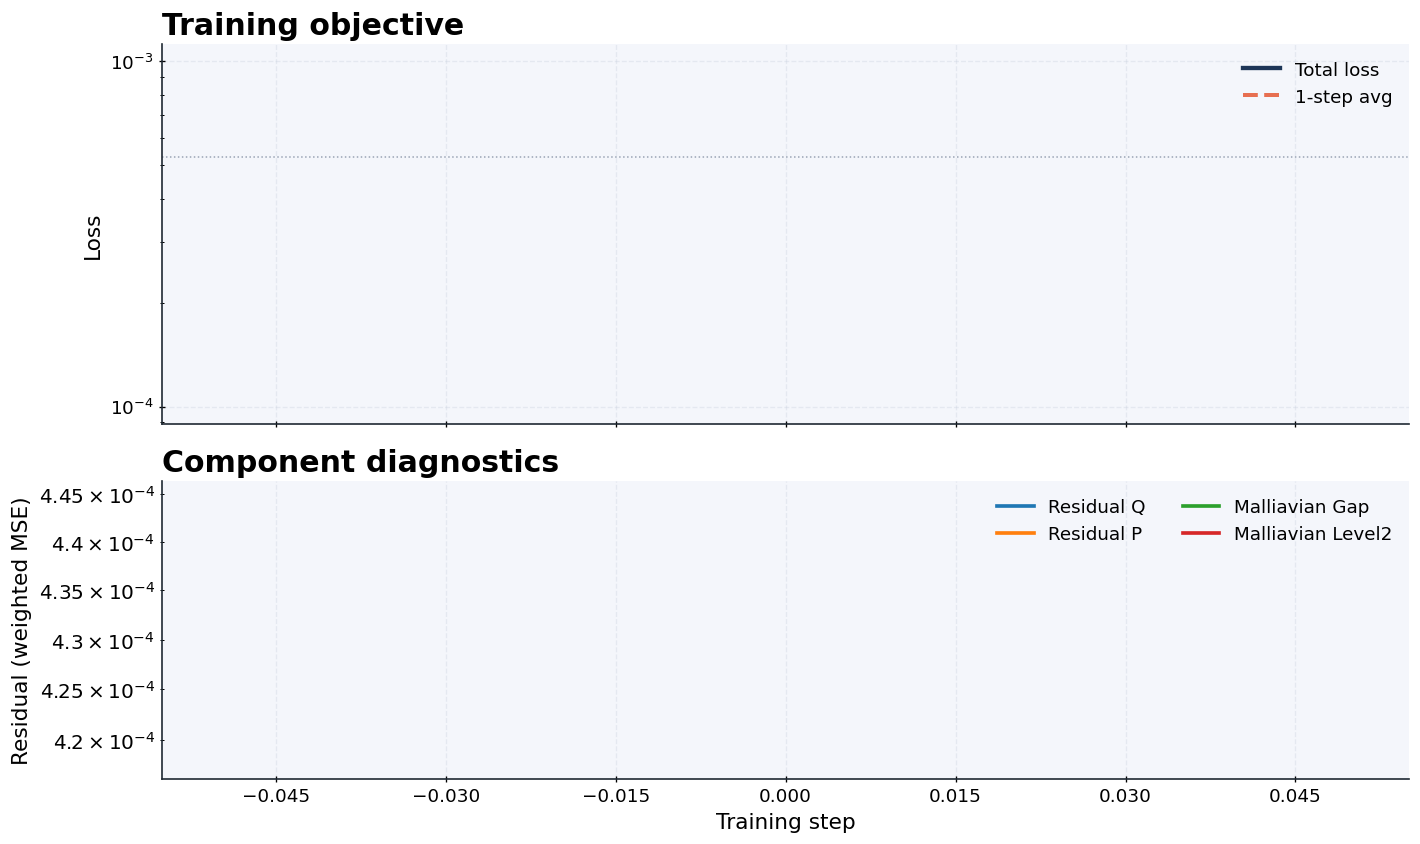

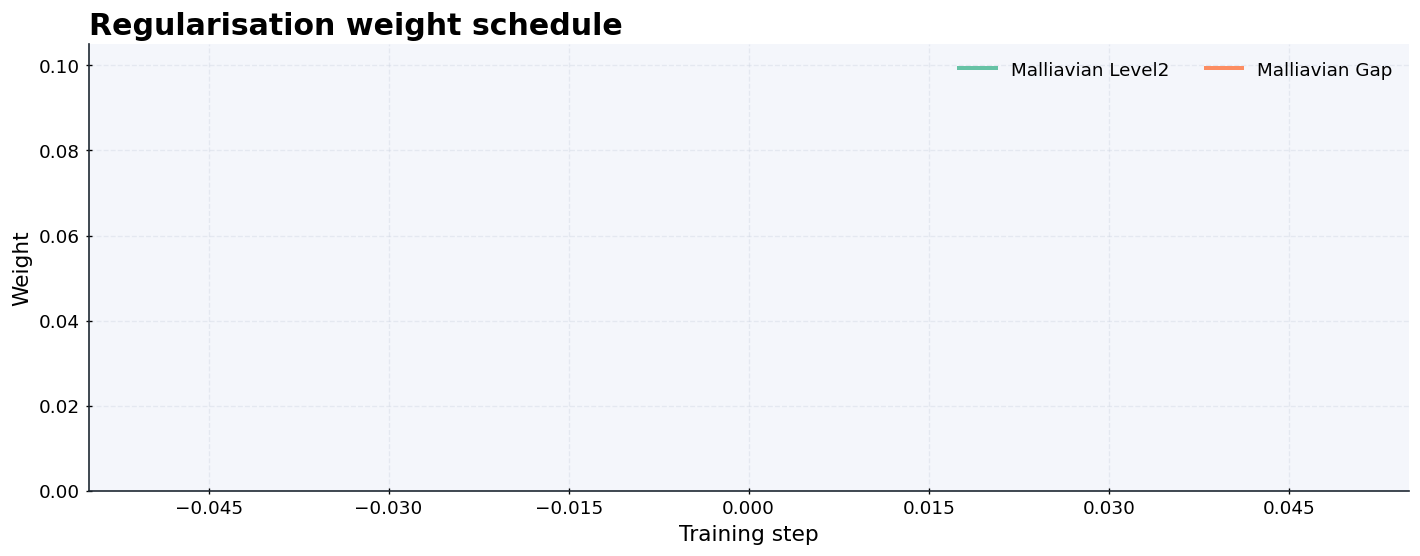

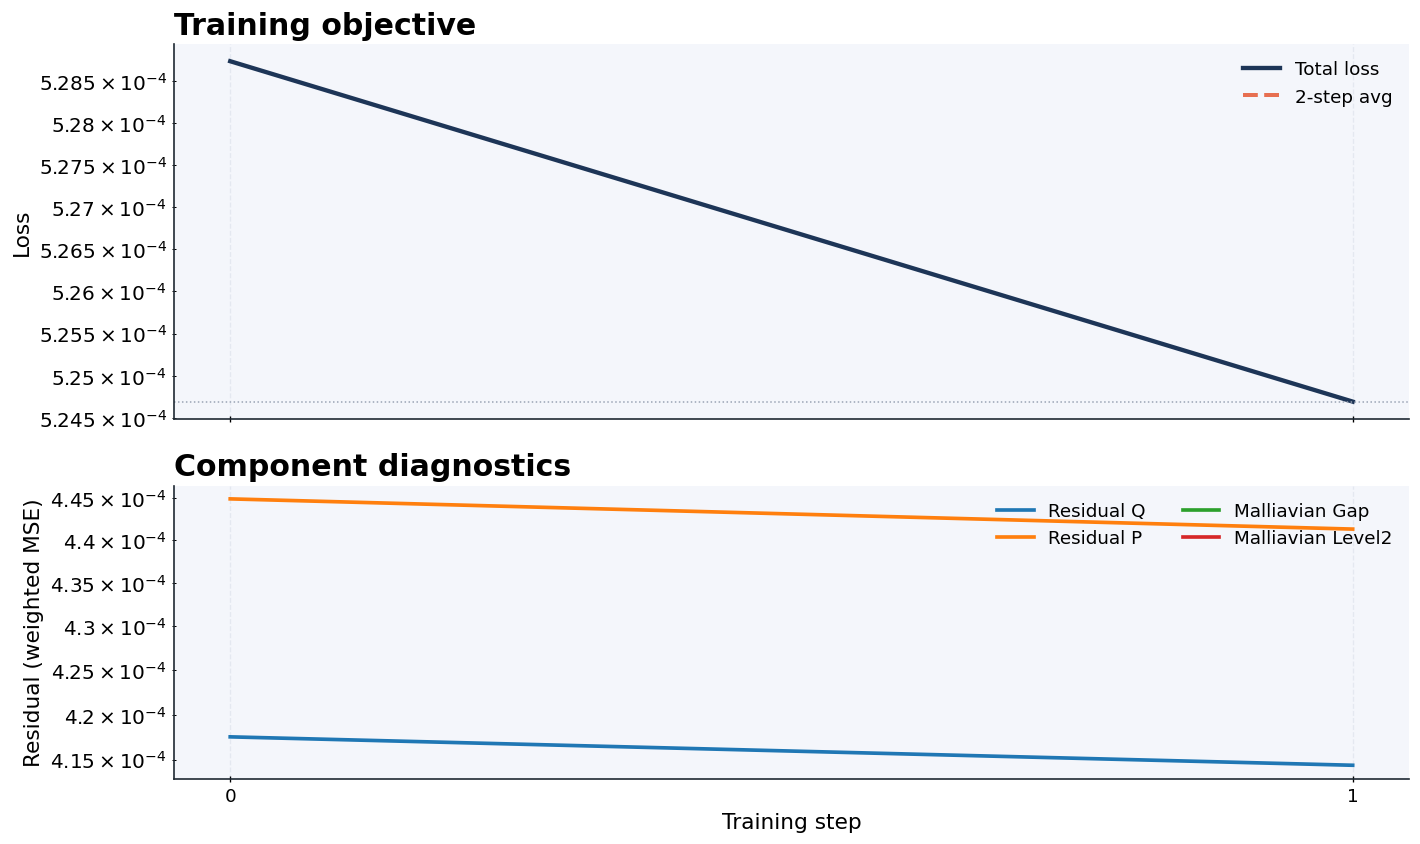

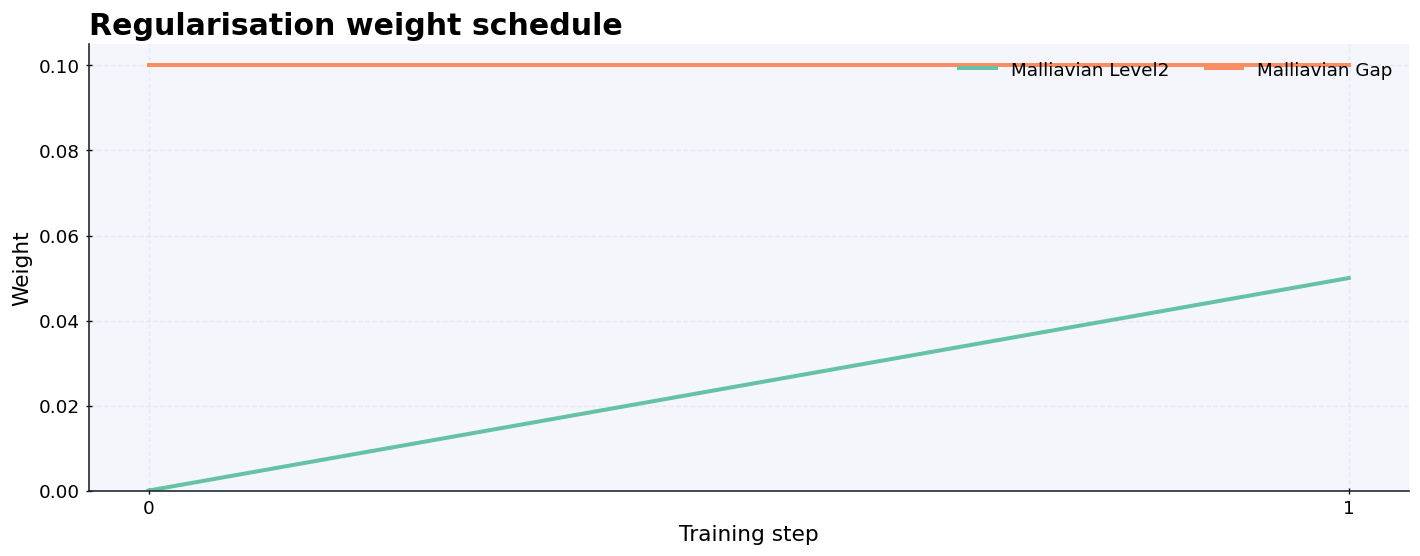

E1009 13:37:28.618093   30211 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %dot.812 = f32[128,16384]{1,0} dot(%constant.672, %constant.1188), lhs_contracting_dims={1}, rhs_contracting_dims={0}, metadata={op_name="jit(while)/while/body/jit(update)/cond/branch_0_fun/jvp(vmap(vmap(jvp(eqx.nn.MLP))))/eqx.nn.Linear/dot_general" source_file="/mnt/d/Dropbox/Dropbox/Fahiz and Max/01 The price of macroeconomic variables in the cross-section of commodity futures/V3/.venv/lib/python3.12/site-packages/jaxopt/_src/cond.py" source_line=24 source_end_line=24 source_column=9 source_end_column=56}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo a

In [ ]:
# Example usage scaffold (disabled by default to avoid accidental long training runs).
if True:
    cfg = default_config()
    rho_star = calibrate_prior_rate(cfg, {i: 0.05 for i in range(cfg.n_trees)})
    print("Calibrated rho prior:", rho_star)

    time_grid = jnp.linspace(0.0, 5.0, 65)
    base_key = random.PRNGKey(cfg.seed)
    model = PriceConsumptionNet(base_key, in_dim=cfg.n_trees - 1, out_dim=cfg.n_trees, rho_prior=cfg.rho)

    hybrid_histories = []
    for stage in range(1):
        model, gd_history = run_training(
            steps=2,
            batch=64,
            times=time_grid,
            config=cfg,
            model=model,
            seed=cfg.seed + 11 * stage,
            plot_interval=1,
            bfgs_interval=10,
            bfgs_kwargs={"maxiter": 12, "tol": 1e-7},
            weight_plot_keys=("malliavian_level2", "malliavian_gap"),
        )
        hybrid_histories.append(("adamw", stage, gd_history))

        model, bfgs_history = run_layerwise_bfgs(
            cycles=2,
            batch=256,
            times=time_grid,
            config=cfg,
            model=model,
            seed=cfg.seed + 37 * stage,
            maxiter=25,
            tol=1e-7,
            resample=False,
        )
        hybrid_histories.append(("bfgs", stage, bfgs_history))

    barycenter = jnp.full((cfg.n_trees,), 1.0 / cfg.n_trees)
    pde_diagnostics = valuation_pde_residual(model, cfg, barycenter, return_terms=True)
    print("Final PDE residual at barycenter:", pde_diagnostics["residual"])

    asset_labels = tuple(f"Tree {i+1}" for i in range(cfg.n_trees))
    shares_paths, g_paths = simulate_dividend_paths(model, cfg, time_grid, batch=128, seed=cfg.seed + 91)

    for label, stage, history in hybrid_histories:
        print(f"Stage {stage} [{label}] final loss:", history["loss"][-1])
        if label == "adamw":
            fig = plot_training_diagnostics(history, rolling=5)
            plt.show(); plt.close(fig)
    fig_weights = plot_weight_schedule(gd_history, weight_keys=("malliavian_level2", "malliavian_gap"))
    fig_pde = plot_pde_residual_breakdown(pde_diagnostics, asset_labels=asset_labels)
    fig_macro = plot_macro_time_series(shares_paths, time_grid, cfg)
    fig_risk = plot_state_risk_profile(shares_paths, g_paths, time_grid, cfg, asset_labels=asset_labels)
    fig_dividend = plot_dividend_yields(shares_paths, g_paths, asset_labels=asset_labels)
    plt.show()


## Next Steps
- Wire SymPy-based consistency checks mirroring Appendix A.7 in `Tex/BSDE_32.tex`.
- Add RQMC stratification (e.g., `jax.random.tfn`) and multilevel switches.
- Couple the notebook with the Lean verification stamps once the blueprint proofs land.